# 01 · Exploratory data analysis — Tangerine "Resilience Rewired"

This notebook tells the story of the data. It **does not contain analysis logic of its own**: every number
comes from the DuckDB warehouse (`warehouse/tangerine.duckdb`) or from functions in `src/tangerine/`,
so the notebook, the tests and the pitch can never disagree.

**Run order:** `python -m tangerine.pipeline` (builds the warehouse) → this notebook.

| Section | Question |
|---|---|
| 1 | What is in the data? |
| 2 | What do the judges' numbers look like across 4,500 customers? |
| 3 | What happens to everyone under each twist card? |
| 4 | The engine on one customer |
| 5 | Who defaults, and could the bank have seen it coming? (the Discovery) |
| 6 | Other findings: pensioners, cards, regions, committed obligations |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "tangerine").exists())
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from tangerine import config, engine, findings, judge_reference
from tangerine.pipeline import connect

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

con = connect(read_only=True)
sql = lambda q: con.execute(q).df()
print("warehouse:", config.WAREHOUSE_PATH)

warehouse: C:\Users\JohnN\OneDrive\Desktop\New folder\datathon2026\warehouse\tangerine.duckdb


## 1 · What is in the data?

Nine official CSVs (read-only, in `Tangerine/data/`) are loaded into the `raw` schema, cleaned into `staging`,
and modelled into `marts`. Row counts match the official brief exactly (a quality check enforces it).

In [2]:
sql('''
select table_name as "table", estimated_size as approx_rows, comment as description
from duckdb_tables()
where schema_name = 'marts' order by table_name
''')

,table,approx_rows,description
0,config_thresholds,12,"Every threshold our flags and plans use, copie..."
1,dim_account,4500,"One row per account: branch, owner, card and l..."
2,dim_district,77,One row per district (the bank's original Czec...
3,fact_account_month,185326,"One row per account per month, from the first ..."
4,mart_balance_slide,808,For every defaulted loan account: average bala...
5,mart_balance_slide_summary,12,Median balance-vs-peak across defaulted accoun...
6,mart_committed_obligations,4500,Monthly amounts each account has committed thr...
7,mart_customer_profile,4500,"One row per account: the judges' numbers (I, F..."
8,mart_default_drivers,22,Default rate by quartile of each pre-loan driv...
9,mart_findings,32,"Every headline number in the pitch, one row pe..."


In [3]:
pd.Series({t: con.execute(f"select count(*) from raw.{t}").fetchone()[0] for t in config.EXPECTED_RAW_ROW_COUNTS},
          name="rows").to_frame().assign(expected=pd.Series(config.EXPECTED_RAW_ROW_COUNTS))

,rows,expected
monthly_summary,185326,185326
transactions,1056320,1056320
accounts,4500,4500
clients,5369,5369
dispositions,5369,5369
cards,892,892
loans,682,682
standing_orders,6471,6471
districts,77,77


**One account, one month** is the grain of `fact_account_month` (185,326 rows). Accounts have 12–72 months of
history, and quiet months (all zeros) are included on purpose: the judges' medians count them.
`money_in` and `money_out` equal the sum of their parts to the cent (quality checks 01 and 02).

In [4]:
sql('''select * from marts.fact_account_month where account_id = 20111 order by month limit 6''')

,account_id,month,month_date,money_in,money_out,cash_deposits,transfers_in,pension_in,interest_in,household_bills,insurance,loan_payments,bank_fees,cash_withdrawals_genuine,card_withdrawals,transfers_out_other,month_end_balance,min_balance,avg_daily_balance,days_below_zero,fixed_costs,discretionary_spending,net_cash_flow,month_number,months_from_end,is_lean_month,was_overdrawn
0,20111,2022-11,2022-11-01,503.42,0.00,503.42,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,503.42,503.42,503.42,0,0.00,0.00,503.42,1,38,True,False
1,20111,2022-12,2022-12-01,"22,132.18","4,467.82","22,067.24",0.00,0.00,64.94,0.00,0.00,0.00,0.00,"4,467.82",0.00,0.00,"18,167.78",503.42,"16,508.05",0,0.00,"4,467.82","17,664.36",2,37,False,False
2,20111,2023-01,2023-01-01,"25,433.96","12,207.84","25,351.40",0.00,0.00,82.56,0.00,0.00,0.00,0.00,"12,207.84",0.00,0.00,"31,393.84","18,167.78","35,404.34",0,0.00,"12,207.84","13,226.12",3,36,False,False
3,20111,2023-02,2023-02-01,130.45,"7,173.68",0.00,0.00,0.00,130.45,0.00,0.00,0.00,0.00,"7,173.68",0.00,0.00,"24,350.67","24,220.16","30,886.10",0,0.00,"7,173.68","-7,043.23",4,35,True,False
4,20111,2023-03,2023-03-01,130.45,"5,663.43",0.00,0.00,0.00,130.45,0.00,0.00,0.00,0.00,"5,663.43",0.00,0.00,"18,817.69","18,687.24","23,624.11",0,0.00,"5,663.43","-5,532.98",5,34,True,False
5,20111,2023-04,2023-04-01,"19,690.86","3,586.84","19,558.97",0.00,0.00,131.89,0.00,0.00,0.00,0.00,"3,586.84",0.00,0.00,"34,921.72","15,230.85","20,299.74",0,0.00,"3,586.84","16,104.02",6,33,False,False


## 2 · The judges' numbers across 4,500 customers

| Judge symbol | Our column | Definition |
|---|---|---|
| I | `typical_income` | median of `money_in` |
| F | `typical_fixed_costs` | median of `household_bills + insurance + loan_payments` (display only) |
| S | `typical_spending` | median of `money_out` |
| H | `typical_household_bills` | median of `household_bills` |
| B | `buffer` | mean `avg_daily_balance`, last 6 months |
| P | `running_loan_payment` | loan payment if status C or D, else 0 |

The SQL version is checked against `judge_reference.py`, an independent pandas version that reads the CSVs:

In [5]:
profile = sql("select * from marts.mart_customer_profile").set_index("account_id").sort_index()
oracle = judge_reference.judge_numbers().sort_index()
judge_cols = ["typical_income", "typical_fixed_costs", "typical_spending", "typical_household_bills", "buffer", "running_loan_payment"]
pd.DataFrame({"max abs difference vs oracle": (profile[judge_cols] - oracle[judge_cols]).abs().max(),
              "median across accounts": profile[judge_cols].median()})

,max abs difference vs oracle,median across accounts
typical_income,0.00,"7,568.26"
typical_fixed_costs,0.00,"1,774.16"
typical_spending,0.00,"7,388.65"
typical_household_bills,0.00,"1,536.68"
buffer,0.00,"22,325.10"
running_loan_payment,0.00,0.00


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in zip(axes, ["typical_income", "typical_spending", "buffer"],
                          ["I · typical income (CAD/month)", "S · typical spending (CAD/month)", "B · buffer (CAD)"]):
    v = profile[col].clip(upper=profile[col].quantile(0.99))
    ax.hist(v, bins=60, color=findings.NEUTRAL)
    ax.axvline(profile[col].median(), color=findings.ALERT, lw=1.5)
    ax.set_title(f"{title}\nmedian ${profile[col].median():,.0f}", fontsize=10, fontweight="normal")
plt.tight_layout()

Edge cases the engine must survive: accounts with **no typical income**, a **negative buffer** (runway 0 under
any shock), **short** or **stale** histories, and **pensioners**. Each is a flag in `mart_customer_profile`:

In [7]:
flags = [c for c in profile.columns if c.startswith(("is_", "has_"))]
profile[flags].sum().sort_values(ascending=False).rename("accounts").to_frame()

,accounts
is_volatile_income,1131
has_card,892
is_pensioner,740
has_loan,682
has_short_history,377
is_balance_sliding,304
has_overdraft_history,288
is_stale_account,76
has_loan_in_debt,45
has_negative_buffer,23


## 3 · Every customer under every twist card (judge formula)

`mart_shock_runways` applies the judges' example twists to all accounts. Runway is rounded to 1 decimal, as the
brief says; NULL = "no shortfall (120+)".

In [8]:
runways = sql("select * from marts.mart_shock_runways").set_index("account_id")
summary = pd.DataFrame({
    "runway 0": (runways == 0).sum(),
    "under 3 months": (runways < 3).sum(),
    "under 6 months": (runways < 6).sum(),
    "no shortfall (120+)": runways.isna().sum(),
    "median (no shortfall = 120)": runways.fillna(120).median(),
})
summary

,runway 0,under 3 months,under 6 months,no shortfall (120+),median (no shortfall = 120)
runway_no_shock,24,60,120,3315,120.00
runway_job_loss_ei55,25,435,1578,234,8.60
runway_bills_up_15,24,65,139,2854,120.00
runway_furnace_1_month,185,284,393,3253,120.00
runway_job_loss_plus_bills,25,504,1740,184,7.80
stress_runway_no_shock,25,412,692,2748,120.00
stress_runway_job_loss_ei55,26,755,1808,192,7.80


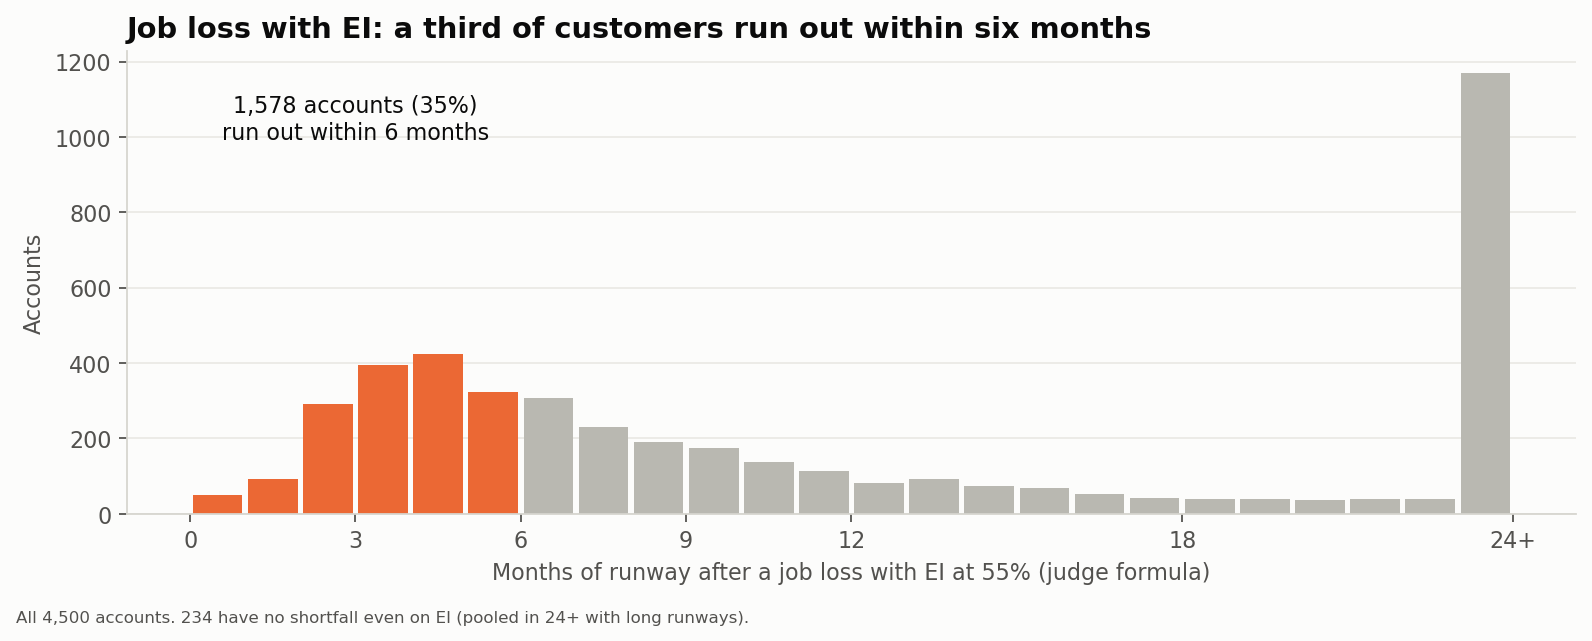

In [9]:
display(Image(ROOT / "reports" / findings.fig_ei_runway(runways.reset_index())))

**Medians hide lean months.** 19% of accounts already have at least one month in five where income falls below
55% of their own median, which is what a month on EI would look like. That is why we add a **stress runway**
(same formula, income = the account's own 25th-percentile month) beside the judge number.

In [10]:
(profile["lean_month_share"] >= 0.20).mean()

np.float64(0.19066666666666668)

## 4 · The engine on one customer

`engine.run(account_id, shock)` returns one JSON-ready dict: profile, judge runway, stress runway, a
month-by-month simulation, a goal plan, a backup plan and plain-English notes. Change the account or the shock
here to rehearse the live twist.

In [11]:
ACCOUNT = 20111
SHOCK = engine.Shock(income_factor=0.55, duration_months=6, bills_increase_pct=0.15)   # or a preset name, e.g. "furnace_1_month"

result = engine.run(ACCOUNT, SHOCK)
print(engine.summary_text(result))

Account 20111 - shock: income at 55% of typical for 6 months, then 0%, household bills +15%
  Typical income (I)      $    6,339.39/month
  Fixed costs (F)         $    2,330.06/month
  Typical spending (S)    $    8,599.60/month
  Household bills (H)     $        0.00/month
  Buffer (B)              $   17,611.86
  Running loan pmt (P)    $    2,330.19/month
  Runway, no shock        7.8 months
  Runway, judge formula   3.4 months
  Runway, stress-adjusted 2.2 months   (lean month: $1,185 in, $652 after the shock)
  Goal plan:   Spending is above income in a typical month, so saving needs a cut: trim discretionary spending by 69% ($5,092/month) to reach a 6-month fund ($51,598) in 12 months.
  Backup plan: If the shock hits (income at 55% of typical for 6 months, then 0%, household bills +15%): keep bills, insurance and loan payments (~$2,330/month), cut discretionary spending by 30% ($2,228/month). Runway goes from 3.4 months to 6.1 months. Reaching 6 months of runway: needs a 29% cu

In [12]:
path = pd.DataFrame(result["simulation"]["rows"])
fig, ax = plt.subplots(figsize=(10, 3.6))
for scenario, color in [("baseline", findings.NEUTRAL), ("shocked", findings.ALERT)]:
    p = path[path.scenario == scenario]
    ax.plot(p.month, p.balance, color=color, lw=2, label=scenario)
ax.axhline(0, color=findings.INK_2, lw=1)
ax.set(xlabel="months from today", ylabel="balance (CAD)", title=f"Account {ACCOUNT}: {result['shock']['description']}")
ax.legend(frameon=False);

In [13]:
pd.DataFrame({name: {"judge runway": engine.judge_runway(engine.get_profile(ACCOUNT), name).label,
                     "stress runway": engine.stress_runway(engine.get_profile(ACCOUNT), name).label}
              for name in engine.PRESETS}).T

,judge runway,stress runway
no_shock,7.8 months,2.4 months
job_loss_ei55,3.4 months,2.2 months
ei55_6_months,3.4 months,2.2 months
bills_up_15,7.8 months,2.4 months
furnace_1_month,4.0 months,1.2 months
job_loss_plus_bills,3.4 months,2.2 months


## 5 · Who defaults — and could the bank have seen it? (the Discovery)

682 loans, 76 defaults (status B or D). To avoid leakage (status D = *currently* in debt, which already shows in
the balances), `mart_loan_preloan` uses **only the months before each loan was granted**: what the bank knew
when it said yes.

### F1 · Going below zero before the loan

In [14]:
drivers = sql("select * from marts.mart_default_drivers")
drivers[drivers.driver == "pre_loan_was_overdrawn"]

,driver,group_label,group_order,loans,defaults,default_rate,min_value,max_value
16,pre_loan_was_overdrawn,never below zero before the loan,1,655,49.00,0.07,NaN,NaN
17,pre_loan_was_overdrawn,went below zero before the loan,2,27,27.00,1.00,NaN,NaN


### F2 / F3 · Unsteady income and heavy payments beat a small buffer

In [15]:
drivers[drivers.driver.isin(["pre_loan_income_cv", "buffer_months", "payment_to_income"])].pivot(
    index="group_label", columns="driver", values="default_rate")

driver,buffer_months,payment_to_income,pre_loan_income_cv
group_label,,,
Q1 (lowest),0.16,0.04,0.04
Q2,0.09,0.11,0.05
Q3,0.06,0.09,0.13
Q4 (highest),0.12,0.20,0.23


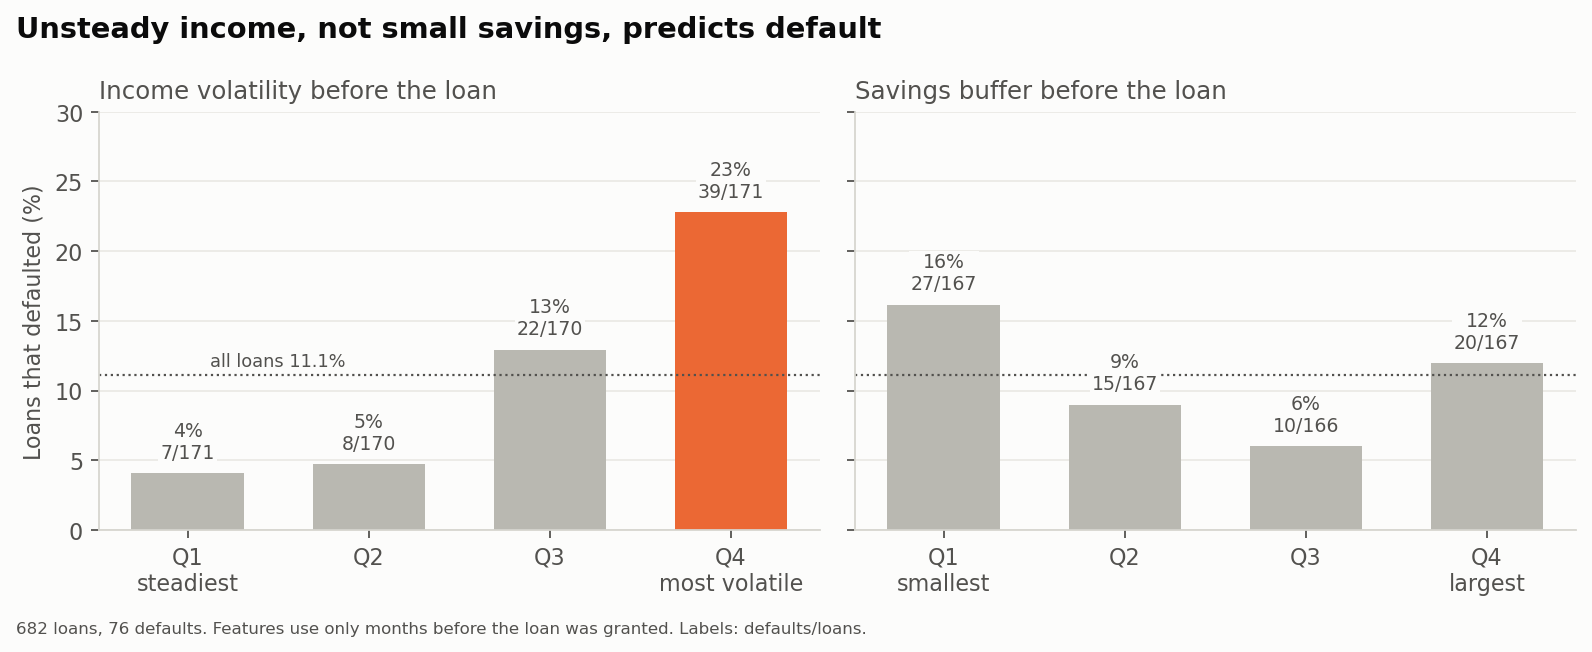

In [16]:
preloan = sql("select * from marts.mart_loan_preloan")
display(Image(ROOT / "reports" / findings.fig_volatility_vs_buffer(drivers, preloan.is_defaulted.mean())))

### F10 · The headline: a stress runway is a better early-warning light

Same judge formula, on pre-loan data, with the new loan payment added to spending. The only change: income is a
**lean month** (25th percentile) instead of a **typical month** (median).
*Analogy: the judges' runway is a fuel gauge; we add a check-engine light.*

In [17]:
auc_table, diffs = findings.stress_vs_judge(preloan)
display(auc_table.round(3), diffs.round(3))

,AUC,CI low,CI high,n loans
"Stress runway (lean-month income, + loan payment)",0.75,0.68,0.81,682
Income volatility (CV),0.71,0.65,0.77,682
Lowest balance,0.68,0.60,0.76,682
Went below zero (yes/no),0.68,0.63,0.73,682
Payment / income,0.67,0.60,0.73,682
Judge EI-55% runway (+ loan payment),0.67,0.59,0.74,682
"Judge runway (median income, + loan payment)",0.64,0.56,0.71,682
Buffer in months of spending,0.56,0.48,0.64,667


,AUC difference,CI low,CI high,share of draws <= 0
stress - judge runway,0.11,0.05,0.18,0.00
stress - buffer months,0.19,0.11,0.27,0.00


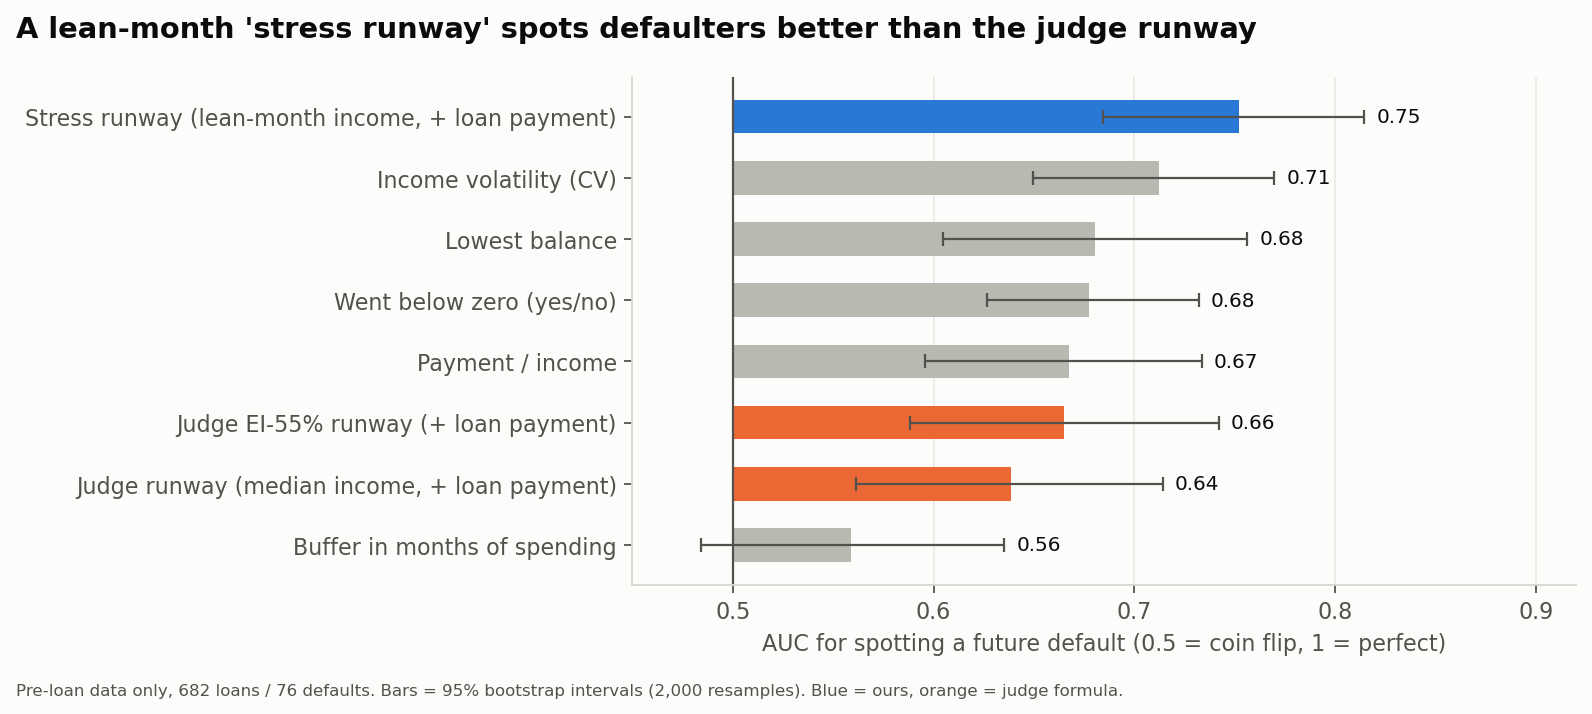

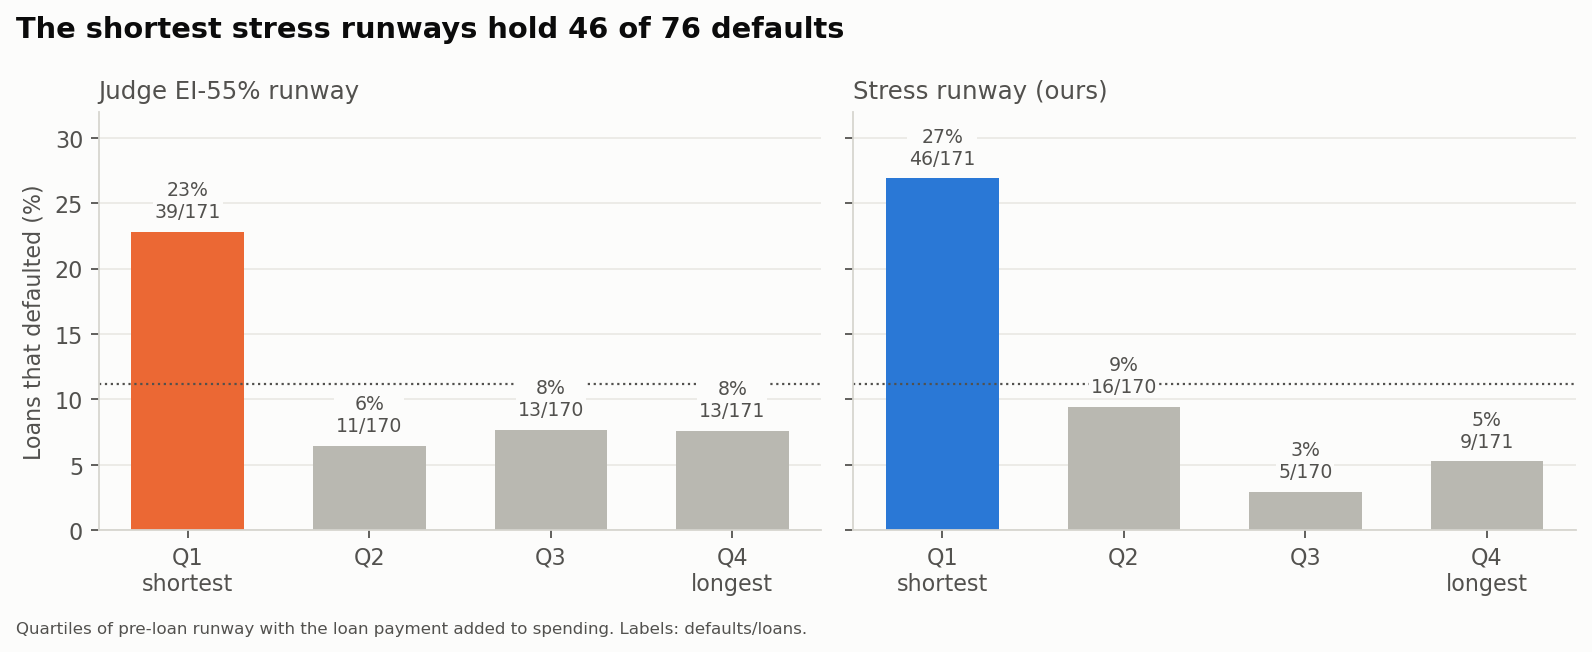

In [18]:
display(Image(ROOT / "reports" / findings.fig_auc(auc_table)))
display(Image(ROOT / "reports" / findings.fig_stress_quartiles(drivers, preloan.is_defaulted.mean())))

### F4 · The balance slides for ~3 months before the first overdraft

,months_before_first_overdraft,accounts,median_balance_vs_12m_peak,mean_balance_vs_12m_peak
0,1,76,0.24,0.34
1,2,76,0.43,0.46
2,3,76,0.58,0.59
3,4,76,0.66,0.62
4,5,76,0.63,0.65
5,6,72,0.75,0.68
6,7,68,0.78,0.72
7,8,65,0.75,0.74
8,9,62,0.85,0.77
9,10,57,0.79,0.76


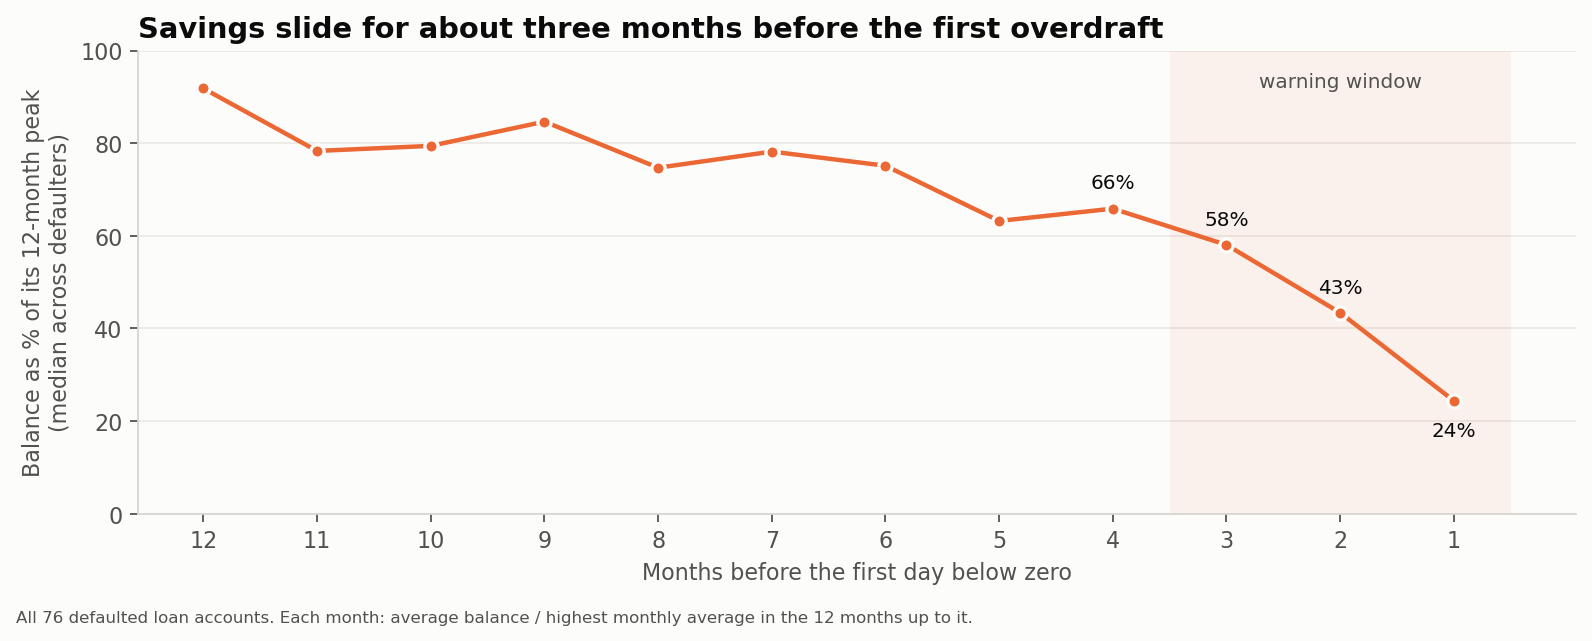

In [19]:
slide = sql("select * from marts.mart_balance_slide_summary")
display(slide)
display(Image(ROOT / "reports" / findings.fig_balance_slide(slide)))

## 6 · Other findings

All headline numbers live in `marts.mart_findings` (with n and source):

In [20]:
f = sql("select finding_id, finding, metric, value, unit, n, source from marts.mart_findings")
f[f.finding_id.isin(["F7", "F8", "F9", "F11"])]

,finding_id,finding,metric,value,unit,n,source
19,F7,Pensioners break the job-loss twist,pensioner accounts (> 30% of income from pensi...,740.00,accounts,4500,mart_customer_profile
20,F7,Pensioners break the job-loss twist,"median owner age, others",39.00,years,3760,mart_customer_profile
21,F7,Pensioners break the job-loss twist,"median owner age, pensioners",71.00,years,740,mart_customer_profile
22,F7,Pensioners break the job-loss twist,"median EI-55% runway (no shortfall = 120), pen...",35.40,months,740,mart_shock_runways
23,F7,Pensioners break the job-loss twist,"median EI-55% runway (no shortfall = 120), others",7.00,months,3760,mart_shock_runways
24,F8,Card holders are wealthier,"median typical income (I), no card","5,758.48",CAD,3608,mart_customer_profile
25,F8,Card holders are wealthier,"median typical income (I), card holders","13,619.67",CAD,892,mart_customer_profile
26,F8,Card holders are wealthier,"median buffer (B), card holders","35,791.98",CAD,892,mart_customer_profile
27,F8,Card holders are wealthier,"median buffer (B), no card","19,145.34",CAD,3608,mart_customer_profile
28,F9,Region barely matters,lowest regional share under 3 months of EI runway,0.08,share,4500,mart_shock_runways


### Committed obligations (standing orders)

`standing_orders.csv` is an undated snapshot of recurring payments. Household bills + insurance + leasing + loan
standing orders, as a share of typical income:

In [21]:
obligations = sql("select * from marts.mart_committed_obligations")
obligations["committed_share_of_income"].describe(percentiles=[.25, .5, .75, .9])

count   4,486.00
mean        0.58
std         7.54
min         0.00
25%         0.13
50%         0.34
75%         0.54
90%         0.65
max       483.36
Name: committed_share_of_income, dtype: float64

### Does local unemployment explain short EI runways? (optional, for Impact)

District unemployment in 2023 vs the share of that district's accounts with under 3 months of EI runway.

In [22]:
by_district = sql('''
select d.district_id, d.district_name, d.unemployment_rate_2023,
       count(*) as accounts,
       avg((r.runway_job_loss_ei55 < 3)::integer) as share_under_3_months
from marts.dim_account a
join marts.dim_district d on d.district_id = a.branch_district_id
join marts.mart_shock_runways r using (account_id)
group by all
''')
print("correlation:", round(by_district[["unemployment_rate_2023", "share_under_3_months"]].corr().iloc[0, 1], 3))
by_district.sort_values("share_under_3_months", ascending=False).head(8)

correlation: -0.095


,district_id,district_name,unemployment_rate_2023,accounts,share_under_3_months
27,61,Trebic,5.74,45,0.23
76,64,Zlin,2.31,92,0.20
31,27,Plzen - jih,1.29,39,0.19
18,15,Cesky Krumlov,3.60,50,0.18
22,68,Frydek - Mistek,4.72,83,0.18
56,44,Chrudim,3.76,50,0.17
51,14,Ceske Budejovice,1.71,41,0.16
23,74,Ostrava - mesto,5.44,135,0.16


Like region (F9), district unemployment barely moves the share of fragile customers. Resilience is about each
customer's own cash flow, which is why the engine works account by account.

### Showcase accounts for the live demo

`python -m tangerine.findings` picks one account per persona and writes `reports/showcase.md`.

In [23]:
display(Markdown((ROOT / "reports" / "showcase.md").read_text(encoding="utf-8").split("## ")[0]))

# Showcase accounts (rehearsal for the live twist)

_Generated by `python -m tangerine.findings`. Runway in months; '-' = no shortfall (120+)._

| Persona | account_id | no_shock | job_loss_ei55 | ei55_6_months | bills_up_15 | furnace_1_month | job_loss_plus_bills |
|---|---:|---:|---:|---:|---:|---:|---:|
| Pensioner | 61810 | - | 36.0 | 36.0 | - | - | 22.8 |
| Volatile cash earner | 56404 | - | 8.7 | 8.7 | - | - | 7.9 |
| Defaulter with a visible balance slide | 59243 | 0.1 | 0.1 | 0.1 | 0.1 | 0.0 | 0.1 |
| Comfortable saver | 72641 | - | 54.8 | 54.8 | - | - | 28.3 |
| Negative buffer | 66692 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |

`ei55_6_months` uses the judge formula, which assumes the shock lasts for good; the engine's month-by-month simulation shows the 6-month version.



In [24]:
con.close()